0 20001
0 [1.0023706  0.80084735 0.58894837 0.40356162 0.28069323 0.19994369
 0.17624764 0.12582399 0.09021521 0.07481965 0.06798775 0.06482989
 0.06537559 0.05982317 0.06697778 0.07155944 0.06357809 0.07797382
 0.09650246 0.11037795 0.08930355 0.08502648 0.07910826 0.09056427
 0.08595085 0.06513916 0.06367384 0.07301135 0.06393447 0.06593824
 0.07832796 0.11842056 0.09391504 0.08796189 0.07840298 0.07105453
 0.06891443 0.07657321 0.1174423  0.18339525 0.21699244 0.17745149
 0.14590509 0.1006092  0.07215848 0.065794   0.05943126 0.06511685
 0.06725877 0.0771542  0.09289281 0.13156144 0.17381105 0.21239226
 0.17259537 0.13728422 0.12025009 0.10608637 0.11778615 0.07123502
 0.06214127 0.05791579 0.0601084  0.05623542 0.06218697 0.06353959
 0.0825203  0.08752497 0.08891791 0.09054216 0.08012335 0.07092603
 0.0865693  0.088452   0.077784   0.08768751 0.0993291  0.08514415
 0.07743531 0.11128002 0.12252379 0.08588591 0.08864061 0.08035238
 0.10938831 0.1142057  0.09980886 0.0974323  0.07164

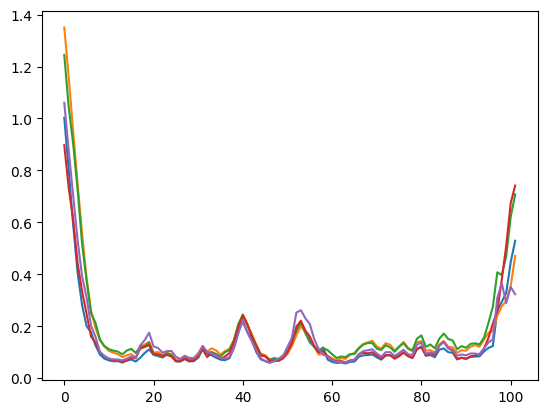

In [1]:
import mdtraj as md
import numpy as np
import matplotlib.pyplot as plt


gleap_target = md.load("../20250801_FUS-RRM/2_md-preparation-2/gleap.target.gro")

for trial in range(5):
    xtc = md.load(f"../20250801_FUS-RRM/6_cmd-{trial+1}/cmd.skip10.whole.target.pbc.xtc", top=gleap_target)
    xtc = xtc.atom_slice(gleap_target.topology.select("name CA"))
    print(trial, xtc.n_frames)
    rmsf = md.rmsf(xtc, xtc[0])
    plt.plot(rmsf)
    print(trial, rmsf)

0 20001
1 20001
2 20001
3 20001
4 20001


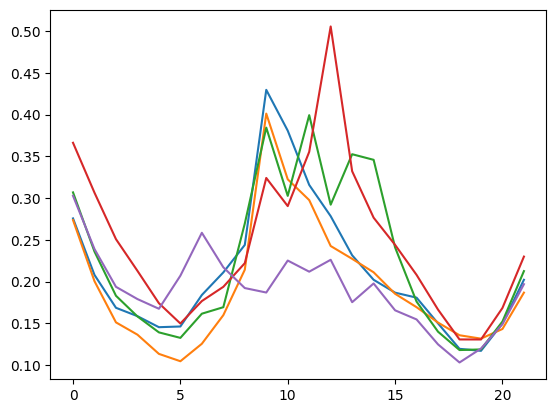

In [2]:
for trial in range(5):
    xtc = md.load(f"../20250801_FUS-RRM/6_cmd-{trial+1}/cmd.skip10.whole.target.pbc.xtc", top=gleap_target)
    xtc = xtc.atom_slice(gleap_target.topology.select("name P"))
    print(trial, xtc.n_frames)
    rmsf = md.rmsf(xtc, xtc[0])
    plt.plot(rmsf)

0 44814
1 50904
2 48864
3 43037
4 55015
5 46107
6 50632
7 37391
8 75437
9 45865
10 47420
11 52783
12 46854
13 87800
14 63459
15 50763
16 40007
17 46976
18 38088
19 38784
20 50824
21 53379
22 33785
23 48056
24 48218
25 48087
26 43895
27 38542
28 52339
29 49470
30 41895
31 31805
32 44531
33 36714
34 46168
35 59338
36 39704
37 41320
38 47157
39 50046
40 40582
41 54207
42 60126
43 45420
44 60297
45 70630
46 73629
47 43471
48 62499
49 78629


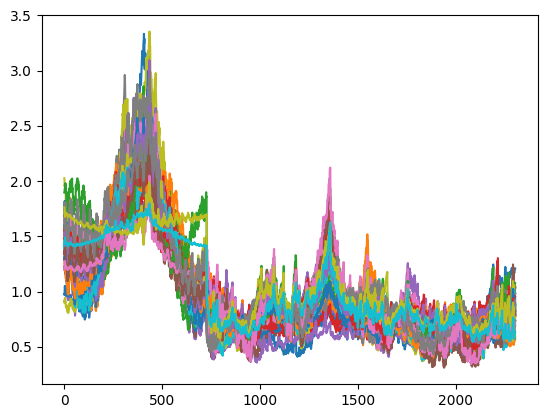

In [3]:
for trial in range(50):
    xtc = md.load(f"../20250801_FUS-RRM/7_pacs-1/trial{trial+1:03}/prd.target.trjcat-all.pbc.skip10.xtc", top=gleap_target)
    print(trial, xtc.n_frames)
    rmsf = md.rmsf(xtc, gleap_target)
    plt.plot(rmsf)

0 44814
1 50904
2 48864
3 43037
4 55015
5 46107
6 50632
7 37391
8 75437
9 45865
10 47420
11 52783
12 46854
13 87800
14 63459
15 50763
16 40007
17 46976
18 38088
19 38784
20 50824
21 53379
22 33785
23 48056
24 48218
25 48087
26 43895
27 38542
28 52339
29 49470
30 41895
31 31805
32 44531
33 36714
34 46168
35 59338
36 39704
37 41320
38 47157
39 50046
40 40582
41 54207
42 60126
43 45420
44 60297
45 70630
46 73629
47 43471
48 62499
49 78629




In [4]:
fig, ax = plt.subplots(1, 50)
fig.set_size_inches(300, 4)

for trial in range(50):
    xtc = md.load(f"../20250801_FUS-RRM/7_pacs-1/trial{trial+1:03}/prd.target.trjcat-all.pbc.skip10.xtc", top=gleap_target)
    print(trial, xtc.n_frames)
    rmsf = md.rmsf(xtc, gleap_target)
    ax[trial].plot(rmsf)

0 20001
1 20001
2 20001
3 20001
4 20001


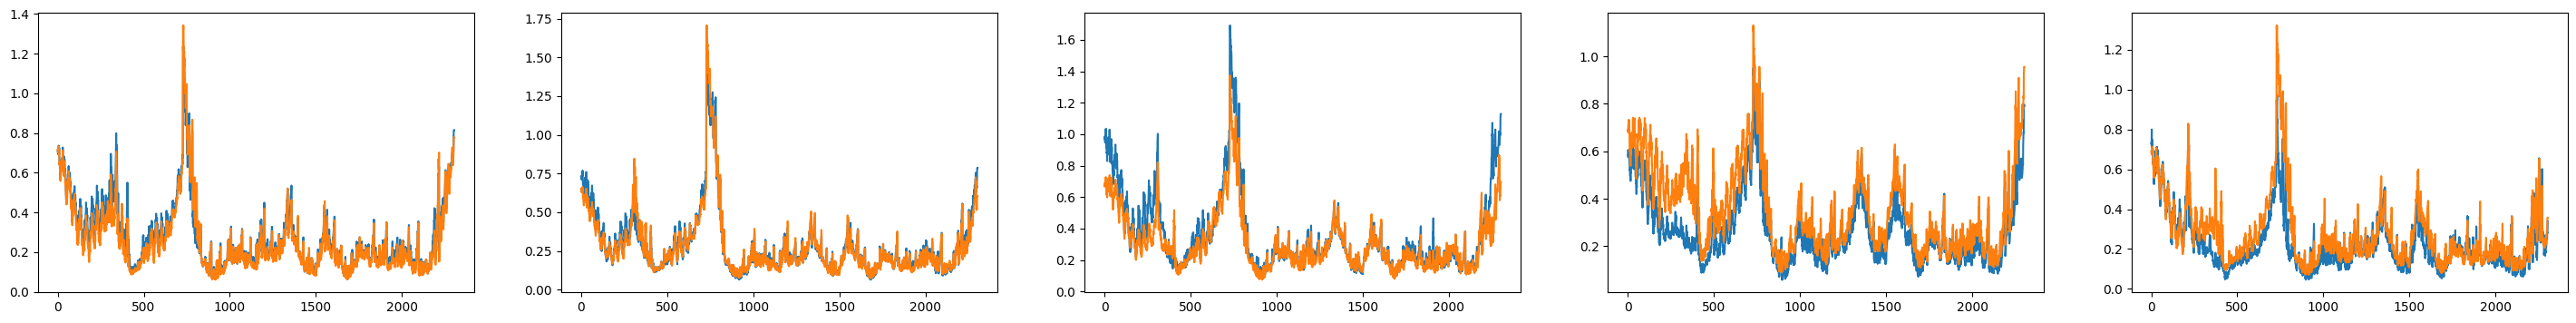

In [5]:
import pickle


fig, ax = plt.subplots(1, 5)
fig.set_size_inches(36, 4)

metastabled_trajs = pickle.load(open("./pickle-cache/pca_tetranucl_all/metastabled_trajs_concat_2.pickle", "rb")).reshape(5, 18000)

for trial in range(5):
    xtc = md.load(f"../20250801_FUS-RRM/6_cmd-{trial+1}/cmd.skip10.whole.target.pbc.xtc", top=gleap_target)
    print(trial, xtc.n_frames)
    ax[trial].plot(md.rmsf(xtc[2001:][metastabled_trajs[trial]==0], xtc[0]))
    ax[trial].plot(md.rmsf(xtc[2001:][metastabled_trajs[trial]==1], xtc[0]))

0 20001
1 20001
2 20001
3 20001
4 20001


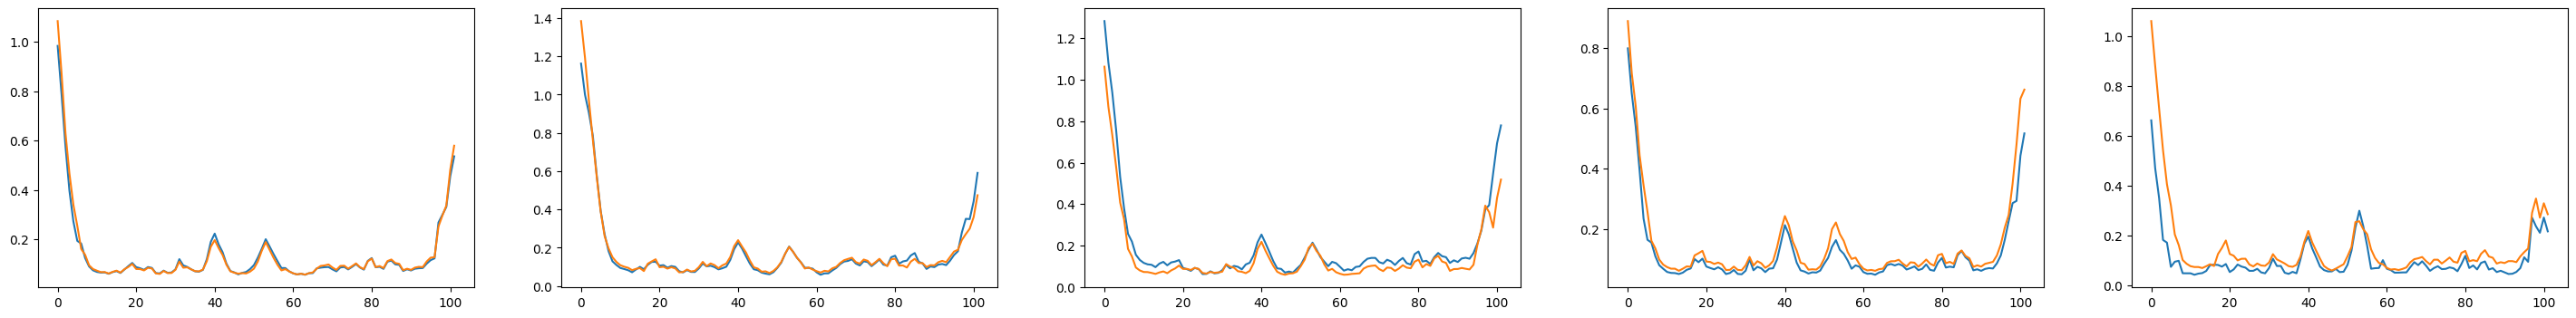

In [6]:
fig, ax = plt.subplots(1, 5)
fig.set_size_inches(36, 4)


for trial in range(5):
    xtc = md.load(f"../20250801_FUS-RRM/6_cmd-{trial+1}/cmd.skip10.whole.target.pbc.xtc", top=gleap_target)
    xtc = xtc.atom_slice(gleap_target.topology.select("name CA"))
    print(trial, xtc.n_frames)
    ax[trial].plot(md.rmsf(xtc[2001:][metastabled_trajs[trial]==0], xtc[0]))
    ax[trial].plot(md.rmsf(xtc[2001:][metastabled_trajs[trial]==1], xtc[0]))

90000
[1.1616907  0.9726911  0.8024548  0.61973286 0.46009412 0.3428506
 0.2284141  0.1922407  0.14001435 0.11648767 0.10071415 0.09350533
 0.09201175 0.08182764 0.09346247 0.10030829 0.08974375 0.13144353
 0.14174451 0.15281257 0.1115025  0.10602736 0.09272492 0.10110393
 0.09704557 0.07229601 0.07024369 0.08447437 0.07568704 0.07569114
 0.09248718 0.12709674 0.10759331 0.11007817 0.1015961  0.08610637
 0.09786538 0.10693986 0.14618275 0.21050332 0.24958353 0.20557795
 0.16593602 0.12488639 0.08935428 0.08510741 0.06956641 0.07719679
 0.08447684 0.10106569 0.13017355 0.16887805 0.22606198 0.25983343
 0.230566   0.19730131 0.15959986 0.12137584 0.11935385 0.09997849
 0.08636747 0.07524468 0.07861016 0.07253741 0.0859497  0.09127004
 0.11509002 0.12929247 0.13540003 0.14133154 0.1194591  0.1090772
 0.13045055 0.12603846 0.10440896 0.11899343 0.1356547  0.11449394
 0.10283665 0.14202532 0.14961393 0.11172028 0.11608296 0.10620794
 0.14092122 0.1563617  0.13549383 0.12891975 0.10092499 0.

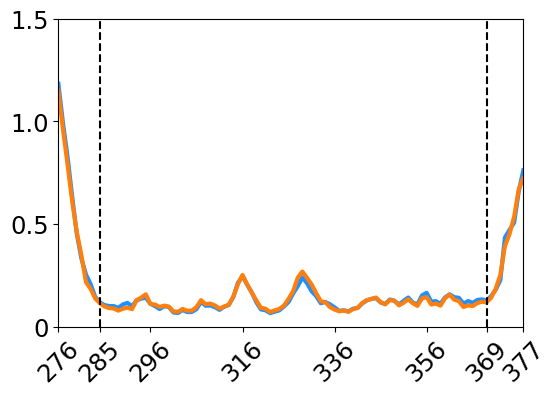

In [7]:
fig, ax = plt.subplots(1, 1)
fig.set_size_inches(6, 4)


tmp = []
for trial in range(5):
    xtc = md.load(f"../20250801_FUS-RRM/6_cmd-{trial+1}/cmd.skip10.whole.target.pbc.xtc", top=gleap_target)[2001:]
    xtc = xtc.atom_slice(gleap_target.topology.select("name CA"))
    tmp.append(xtc)
xtcs_all = md.join(tmp)
print(xtcs_all.n_frames)

ax.plot(md.rmsf(xtcs_all[np.concatenate(metastabled_trajs)==0], xtcs_all[0]), color="#1E90FF", linewidth=3)
ax.plot(md.rmsf(xtcs_all[np.concatenate(metastabled_trajs)==1], xtcs_all[0]), color="tab:orange", linewidth=3)
ax.axvline(9, color="black", linestyle="--")
ax.axvline(93, color="black", linestyle="--")
ax.set_xlim(0, 101)
ax.set_xticks([0, 9, 20, 40, 60, 80, 93, 101], [276, 285, 296, 316, 336, 356, 369, 377], rotation=45)
ax.tick_params(axis='x', labelsize=17.5)
ax.set_yticks([0, 0.5, 1.0, 1.5], [0, 0.5, 1.0, 1.5])
# ax.set_xticks([0, 0.3, 0.6, 0.9, 1.2, 1.5], [0, 0.3, 0.6, 0.9, 1.2, 1.5], rotation=45)
ax.tick_params(axis='y', labelsize=17.5)

print(md.rmsf(xtcs_all, xtcs_all[0]))

0 20001
1 20001
2 20001
3 20001
4 20001


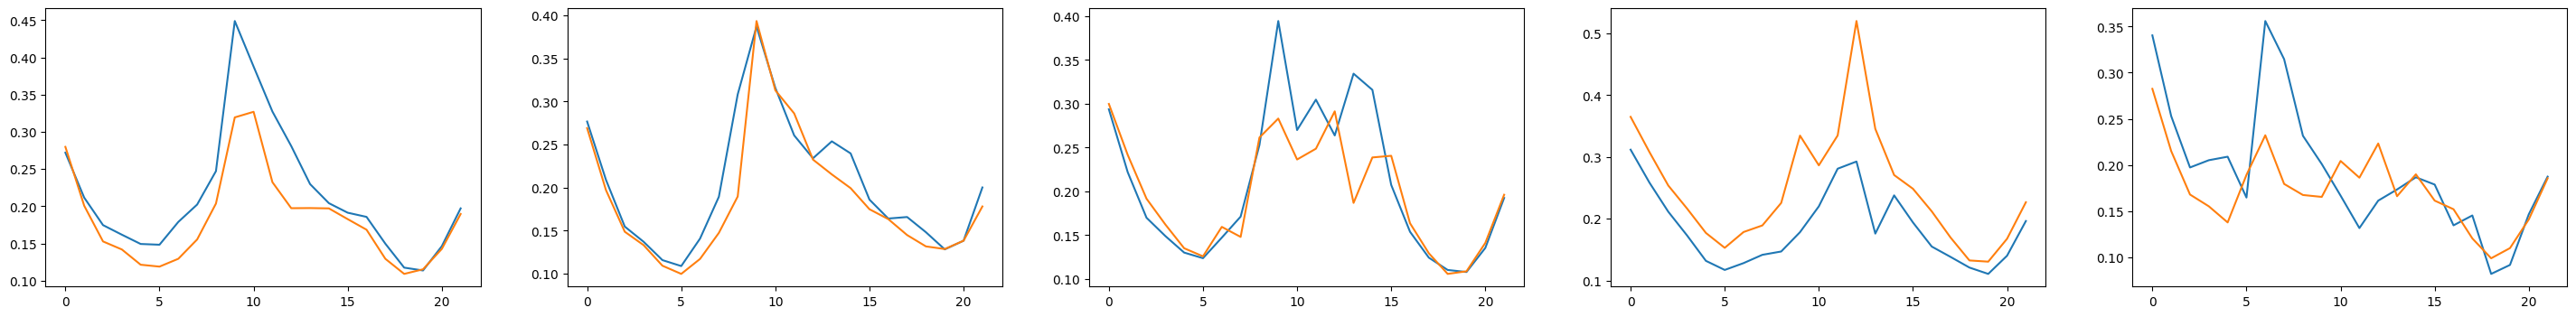

In [8]:
fig, ax = plt.subplots(1, 5)
fig.set_size_inches(36, 4)

for trial in range(5):
    xtc = md.load(f"../20250801_FUS-RRM/6_cmd-{trial+1}/cmd.skip10.whole.target.pbc.xtc", top=gleap_target)
    xtc = xtc.atom_slice(gleap_target.topology.select("name P"))
    print(trial, xtc.n_frames)
    ax[trial].plot(md.rmsf(xtc[2001:][metastabled_trajs[trial]==0], xtc[0]))
    ax[trial].plot(md.rmsf(xtc[2001:][metastabled_trajs[trial]==1], xtc[0]))